# Task 3 – Background removal using only colour, step by step

A visual notebook to understand every step of our background-removal method (M2) and to take figures for the slides.
It uses the **final version of the method with the 15-px wall strip** (the organisers guarantee at least 15 px of
wall on every side of the painting).

**Goal:** for each QSD2 photo (a painting hanging on a wall), build a **binary mask**: 1 = painting, 0 = wall. Only the
**colour** may be used (no edge / contour / object detectors).

**The idea in one sentence:** the border of the photo is always wall, so we learn the colour of the wall from a thin
strip along the border, and every pixel whose colour is far from that wall colour is painting.

| Step | What | Why |
|---|---|---|
| 1 | Downscale to 400 px | speed, and the same behaviour for small and large photos |
| 2 | Median filter 5×5 | remove texture and noise, keep the edges |
| 3 | Convert to Lab | separate brightness (L) from colour (a, b) |
| 4 | Take the 15-px border strip (full resolution) | pixels that are guaranteed to be wall |
| 5 | Robust Gaussian model of the wall | mean colour + how the wall varies |
| 6 | Mahalanobis distance of every pixel | distance measured in units of the wall's own variation |
| 7 | log + Otsu threshold | automatic threshold per image: painting / wall |
| 8 | Post-processing of the mask | morphology, largest component, fill holes, row/column fill |
| 9 | Back to full size, crop the bounding box | the crop goes to retrieval (Task 5) |

All figures are saved in `figures/bg_explained_*.png`. Put this notebook in `Project/week2/`.

In [1]:
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Ellipse, Rectangle

TEAL, ORANGE, GREY, RED, INK, BLUE = "#1B7F79", "#F0A830", "#9AA5AB", "#C8553D", "#222222", "#3D6FC8"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)


def savefig(name):
    plt.savefig(FIG / f"bg_explained_{name}.png")


def find_dir(*candidates, pattern="*.jpg"):
    for c in map(Path, candidates):
        if c.is_dir():
            if any(c.glob(pattern)):
                return c
            for sub in sorted(p for p in c.iterdir() if p.is_dir()):
                if any(sub.glob(pattern)):
                    return sub
    return None


QSD2_DIR = find_dir("qsd2_w2", "qsd2_w1")
paths = sorted(QSD2_DIR.glob("*.jpg"))
IMGS = [cv2.imread(str(p)) for p in paths]                                   # full resolution, BGR
GTS = [cv2.imread(str(p.with_suffix(".png")), cv2.IMREAD_GRAYSCALE) > 0 for p in paths]
print(f"QSD2: {len(IMGS)} photos from {QSD2_DIR}; sizes from {min(min(i.shape[:2]) for i in IMGS)} "
      f"to {max(max(i.shape[:2]) for i in IMGS)} px")

rgb = lambda x: x[..., ::-1]                                                 # OpenCV is BGR, matplotlib wants RGB
MAIN = 29                                                                    # the photo we follow through all the steps

QSD2: 30 photos from qsd2_w2/qsd2_w1; sizes from 373 to 2724 px


## The method (same code as `c1-week2-15px.ipynb`)

`run_steps` does exactly what `compute_mask` does in the main notebook, but it also returns every intermediate result so
we can plot it.

In [2]:
WORK_SIDE = 400      # step 1: the mask is computed on a copy with longest side 400 px
BORDER_PX = 15       # step 4: the organisers guarantee at least 15 px of wall on every side
KEEP = 0.8           # step 5: robust estimate with the 80% of strip pixels closest to the median colour


def resize_max(img, max_side=WORK_SIDE):
    s = max_side / max(img.shape[:2])
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img


def border_mask(h, w, t):
    m = np.zeros((h, w), bool)
    m[:t], m[-t:], m[:, :t], m[:, -t:] = True, True, True, True
    return m


def robust_gaussian(P, keep=KEEP):
    """Mean / covariance of the dominant colour: the `keep` fraction of pixels closest to the median colour."""
    d = np.linalg.norm(P - np.median(P, 0), axis=1)
    kept = d <= np.quantile(d, keep)
    return P[kept].mean(0), np.cov(P[kept].T) + np.eye(3), kept


def mahalanobis_map(x, mu, cov):
    d = x.reshape(-1, 3).astype(np.float64) - mu
    return np.sqrt(np.einsum("ij,jk,ik->i", d, np.linalg.inv(cov), d)).reshape(x.shape[:2])


def otsu_threshold(v, nbins=256, return_curve=False):
    """Otsu: the threshold that maximises the between-class variance of the histogram of v."""
    hist, edges = np.histogram(v, nbins)
    p, c = hist / hist.sum(), (edges[:-1] + edges[1:]) / 2
    w0 = np.cumsum(p); w1 = 1 - w0
    m0 = np.cumsum(p * c) / np.maximum(w0, 1e-12)
    m1 = ((p * c).sum() - np.cumsum(p * c)) / np.maximum(w1, 1e-12)
    between = w0 * w1 * (m0 - m1) ** 2
    t = c[np.argmax(between)]
    return (t, c, between) if return_curve else t


def struct_el(shape, frac):
    s = min(shape)
    return cv2.getStructuringElement(cv2.MORPH_RECT, (max(1, int(frac * s)) | 1,) * 2)


def largest_component(m):
    n, lbl, stats, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8), connectivity=8)
    return m.astype(bool) if n <= 1 else lbl == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])


def fill_holes(m):
    """Holes = background pixels that cannot be reached from the image border (flood fill from a corner)."""
    pad = cv2.copyMakeBorder(m.astype(np.uint8), 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
    ff = pad.copy()
    cv2.floodFill(ff, np.zeros((pad.shape[0] + 2, pad.shape[1] + 2), np.uint8), (0, 0), 1)
    return m.astype(bool) | (ff == 0)[1:-1, 1:-1]


def row_col_fill(m):
    rows, cols = np.zeros_like(m, bool), np.zeros_like(m, bool)
    for y in np.where(m.any(1))[0]:
        xs = np.where(m[y])[0]; rows[y, xs[0]:xs[-1] + 1] = True
    for x in np.where(m.any(0))[0]:
        ys = np.where(m[:, x])[0]; cols[ys[0]:ys[-1] + 1, x] = True
    return rows & cols


def run_steps(img, border_px=BORDER_PX, keep=KEEP):
    """Full-resolution BGR photo -> dict with every intermediate result; s['mask'] is the final full-size mask."""
    s = {}
    H, W = img.shape[:2]
    s["small_raw"] = resize_max(img)                                          # 1. downscale
    s["small"] = cv2.medianBlur(s["small_raw"], 5)                            # 2. median filter
    s["lab"] = cv2.cvtColor(s["small"], cv2.COLOR_BGR2LAB).astype(np.float64)  # 3. Lab
    full_lab = cv2.cvtColor(cv2.medianBlur(img, 5), cv2.COLOR_BGR2LAB)        # 4. 15-px strip at full resolution
    s["P"] = full_lab[border_mask(H, W, border_px)].astype(np.float64)
    s["mu"], s["cov"], s["kept"] = robust_gaussian(s["P"], keep)              # 5. robust Gaussian model
    s["maha"] = mahalanobis_map(s["lab"], s["mu"], s["cov"])                   # 6. Mahalanobis distance
    s["eucl"] = np.linalg.norm(s["lab"] - s["mu"], axis=2)                    #    (Euclidean, only for comparison)
    s["ld"] = np.log1p(s["maha"])                                             # 7. log + Otsu
    s["thr"] = otsu_threshold(s["ld"])
    s["raw"] = s["ld"] > s["thr"]
    m = s["raw"].astype(np.uint8)                                             # 8. post-processing
    s["close"] = cv2.morphologyEx(m, cv2.MORPH_CLOSE, struct_el(m.shape, 0.03)).astype(bool)
    s["open"] = cv2.morphologyEx(s["close"].astype(np.uint8), cv2.MORPH_OPEN, struct_el(m.shape, 0.02)).astype(bool)
    s["largest"] = largest_component(s["open"])
    s["holes"] = fill_holes(s["largest"])
    s["rowcol"] = row_col_fill(s["holes"])
    post = s["rowcol"] if s["rowcol"].any() else np.ones_like(s["rowcol"])
    s["mask"] = cv2.resize(post.astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST).astype(bool)  # 9.
    return s


def prf(pred, gt):
    tp = np.sum(pred & gt); fp = np.sum(pred & ~gt); fn = np.sum(~pred & gt)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)


def error_overlay(img, pred, gt):
    """Green = correct painting, red = wall taken as painting (FP), blue = painting lost (FN). img is BGR."""
    out = (img.astype(np.float32) * 0.45).astype(np.uint8)
    out[pred & gt] = (img[pred & gt] * 0.5 + np.array([60, 200, 60]) * 0.5).astype(np.uint8)
    out[pred & ~gt] = (0, 0, 230); out[~pred & gt] = (230, 60, 0)
    return out


t0 = time.time()
STEPS = [run_steps(im) for im in IMGS]
print(f"30 masks in {time.time() - t0:.1f}s")
S = STEPS[MAIN]

30 masks in 2.2s


## 0. The task and the key observation

Each QSD2 photo has its ground-truth mask (white = painting). Our mask has to look like it.

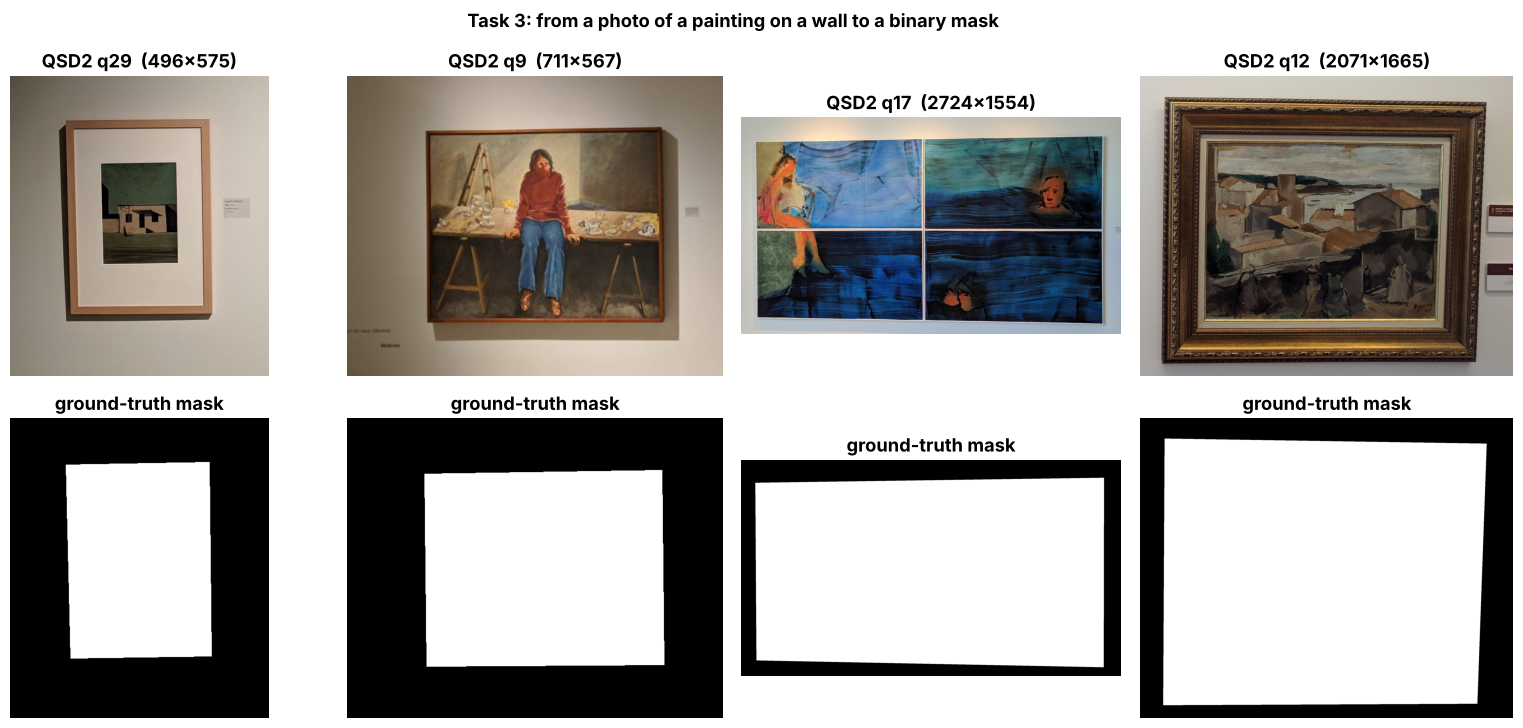

In [3]:
ex = [MAIN, 9, 17, 12]
fig, axes = plt.subplots(2, 4, figsize=(16, 7.4))
for k, i in enumerate(ex):
    axes[0, k].imshow(rgb(IMGS[i])); axes[0, k].set_title(f"QSD2 q{i}  ({IMGS[i].shape[1]}×{IMGS[i].shape[0]})")
    axes[1, k].imshow(GTS[i], cmap="gray"); axes[1, k].set_title("ground-truth mask")
for a in axes.ravel(): a.axis("off")
plt.suptitle("Task 3: from a photo of a painting on a wall to a binary mask", fontweight="bold")
plt.tight_layout(); savefig("0_task"); plt.show()

**The key observation:** the painting is always in the middle and the **border of the photo is wall**. The organisers
guarantee **at least 15 px of wall** on every side. In QSD2 the painting is always further away (at least 60 px), but in
the test set it could be as close as 15 px, so the method must not rely on more than that.

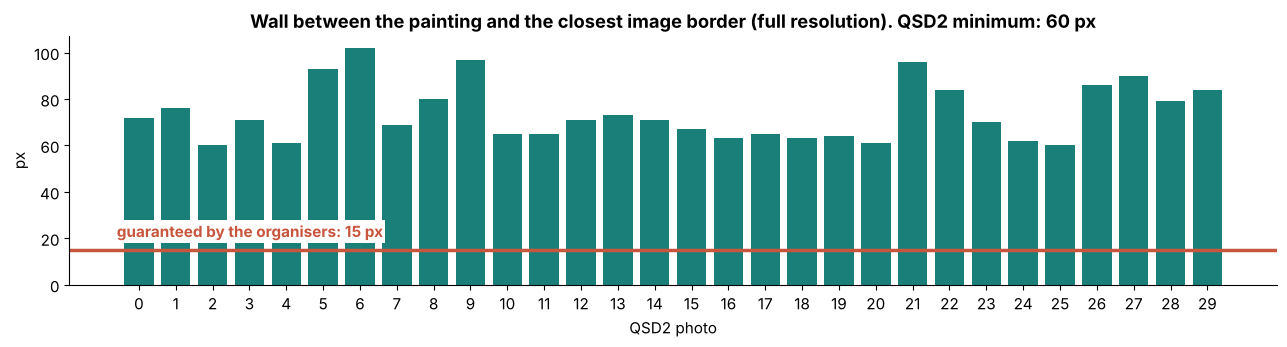

In [4]:
gaps = []
for g in GTS:
    ys, xs = np.where(g); H, W = g.shape
    gaps.append(min(ys.min(), xs.min(), H - 1 - ys.max(), W - 1 - xs.max()))
gaps = np.array(gaps)

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar(range(30), gaps, color=TEAL)
ax.axhline(15, color=RED, lw=2.5)
ax.text(-0.6, 19, "guaranteed by the organisers: 15 px", color=RED, va="bottom", fontweight="bold",
        bbox=dict(fc="white", ec="none", pad=1.5))
ax.set_xticks(range(30)); ax.set_xlabel("QSD2 photo"); ax.set_ylabel("px")
ax.set_title(f"Wall between the painting and the closest image border (full resolution). QSD2 minimum: {gaps.min()} px")
plt.tight_layout(); savefig("0_wall_gap"); plt.show()

## Step 1 – Downscale to 400 px

The photo is resized so that its **longest side is 400 px** (keeping the proportions). The mask is computed on this small
copy and, at the end, enlarged back to the original size.

- **Speed:** a 2307×1908 photo has 4.4 million pixels, its 400 px copy about 130 000 (30× fewer). Every following step is
  30× faster.
- **A mask does not need detail:** we only want to know *where the rectangle of the painting is*. One pixel of the small
  copy is ~5 pixels of the original: the edge of the mask moves by at most a few original pixels.
- **Same behaviour for every photo:** QSD2 has photos from 390 to 2724 px. Working always at 400 px, the parameters
  (e.g. the sizes of the morphological filters, a % of the side) mean the same in all of them.

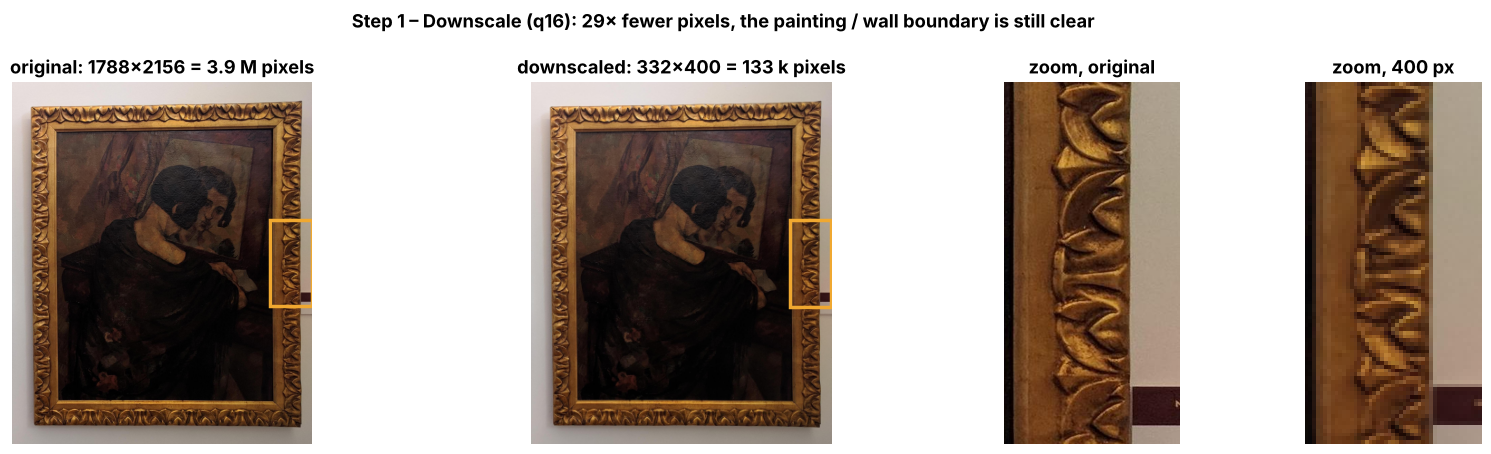

In [5]:
big = 16
img = IMGS[big]; small = STEPS[big]["small_raw"]
H, W = img.shape[:2]; h, w = small.shape[:2]
# zoom on the same region (the label on the wall, right of the frame) in both versions
y0, y1, x0, x1 = 0.38, 0.62, 0.86, 1.0
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 0.6, 0.6]))
axes[0].imshow(rgb(img)); axes[0].set_title(f"original: {W}×{H} = {W * H / 1e6:.1f} M pixels")
axes[1].imshow(rgb(small)); axes[1].set_title(f"downscaled: {w}×{h} = {w * h / 1e3:.0f} k pixels")
for a, (im_, hh, ww) in zip(axes[:2], [(img, H, W), (small, h, w)]):
    a.add_patch(Rectangle((x0 * ww, y0 * hh), (x1 - x0) * ww - 1, (y1 - y0) * hh, fill=False, ec=ORANGE, lw=2.5))
axes[2].imshow(rgb(img[int(y0 * H):int(y1 * H), int(x0 * W):int(x1 * W)])); axes[2].set_title("zoom, original")
axes[3].imshow(rgb(small[int(y0 * h):int(y1 * h), int(x0 * w):int(x1 * w)]), interpolation="nearest"); axes[3].set_title("zoom, 400 px")
for a in axes: a.axis("off")
plt.suptitle(f"Step 1 – Downscale (q{big}): {W * H / (w * h):.0f}× fewer pixels, the painting / wall boundary is still clear",
             fontweight="bold")
plt.tight_layout(); savefig("1_downscale"); plt.show()

## Step 2 – Median filter 5×5

For every pixel we look at its **25 neighbours** (a 5×5 square centred on it), **sort** their values and the pixel gets
**the middle one** (the median, the 13th of 25). It is done for each colour channel.

The toy example below is one row of pixels: wall (200) with a dark speck (a crack, noise, a pore of the wall) and then
the edge with a dark frame (50). We compare the median with the **mean** (a normal blur) over the same 5 pixels.

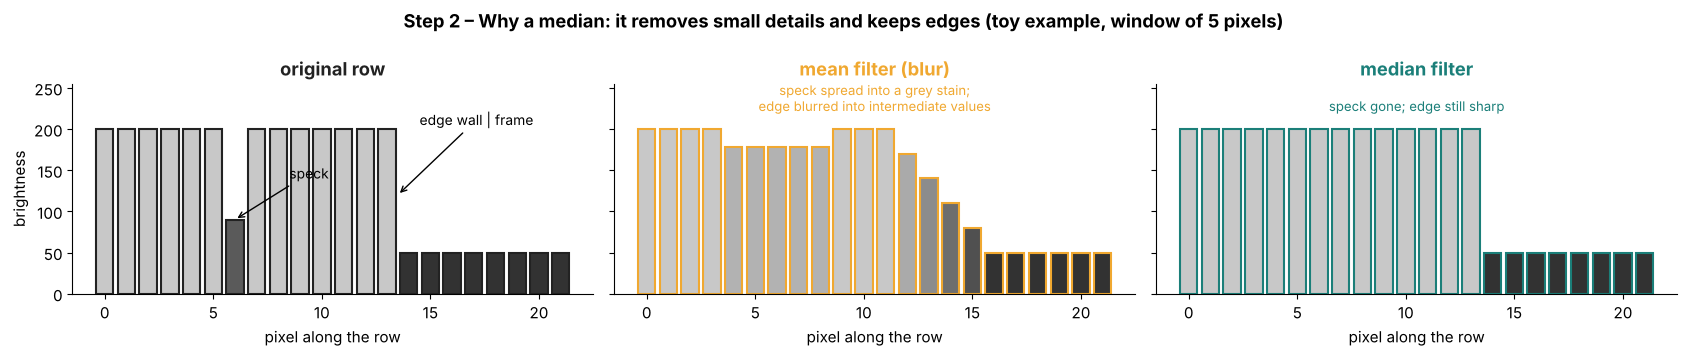

In [6]:
row = np.array([200] * 6 + [90] + [200] * 7 + [50] * 8, float)
k = 5
padded = np.pad(row, k // 2, mode="edge")
win = np.lib.stride_tricks.sliding_window_view(padded, k)
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6), sharey=True)
for ax, (vals, name, col) in zip(axes, [(row, "original row", INK), (win.mean(1), "mean filter (blur)", ORANGE),
                                        (np.median(win, 1), "median filter", TEAL)]):
    ax.bar(range(len(row)), vals, color=[plt.cm.gray(v / 255) for v in vals], ec=col, lw=1.5)
    ax.set_title(name, color=col); ax.set_xlabel("pixel along the row"); ax.set_ylim(0, 255)
axes[0].set_ylabel("brightness")
axes[0].annotate("speck", (6, 90), (8.5, 140), arrowprops=dict(arrowstyle="->"), fontsize=10)
axes[0].annotate("edge wall | frame", (13.5, 120), (14.5, 205), arrowprops=dict(arrowstyle="->"), fontsize=10)
axes[1].text(10.5, 222, "speck spread into a grey stain;\nedge blurred into intermediate values", ha="center", fontsize=9.5, color=ORANGE)
axes[2].text(10.5, 222, "speck gone; edge still sharp", ha="center", fontsize=9.5, color=TEAL)
plt.suptitle("Step 2 – Why a median: it removes small details and keeps edges (toy example, window of 5 pixels)", fontweight="bold")
plt.tight_layout(); savefig("2_median_toy"); plt.show()

The median always returns a value that **already exists** in the neighbourhood (either wall or frame), never an invented
one in between. A blur creates intermediate colours at the boundary, which are neither wall nor painting.

The same on a real photo (zoom on the frame, the passe-partout and the wall of q29):

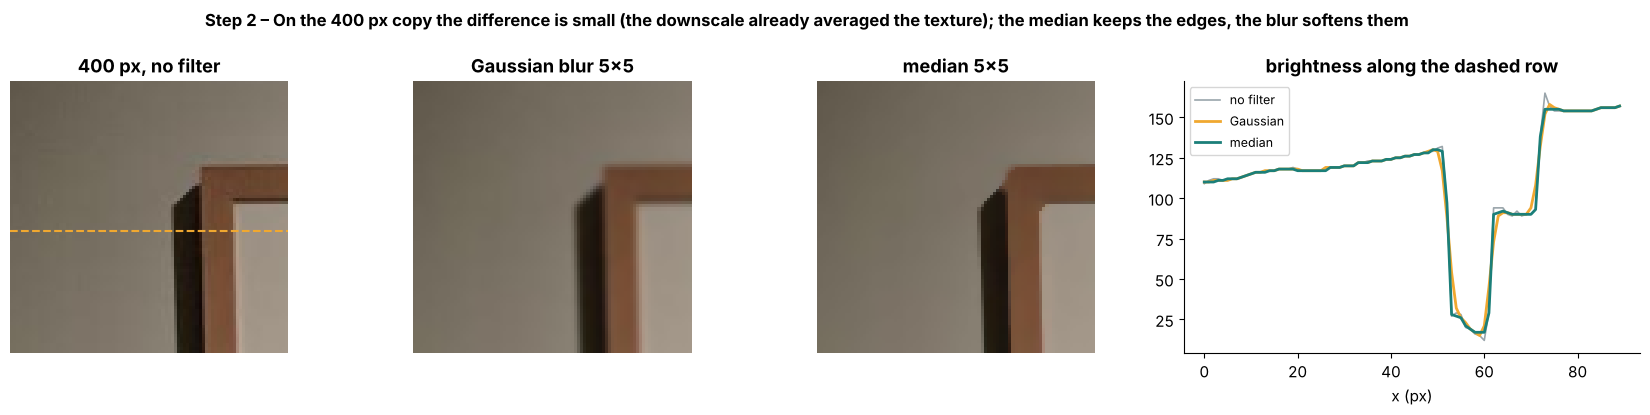

In [7]:
sr = S["small_raw"]; h, w = sr.shape[:2]
zy, zx = slice(int(0.08 * h), int(0.30 * h)), slice(int(0.04 * w), int(0.30 * w))
gauss = cv2.GaussianBlur(sr, (5, 5), 0)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.3]))
for a, (im_, name) in zip(axes, [(sr, "400 px, no filter"), (gauss, "Gaussian blur 5×5"), (S["small"], "median 5×5")]):
    a.imshow(rgb(im_[zy, zx]), interpolation="nearest"); a.set_title(name); a.axis("off")
yrow = int(0.20 * h)
axes[0].axhline(yrow - zy.start, color=ORANGE, lw=1.5, ls="--")
xs = np.arange(zx.start, zx.stop)
for im_, name, col, lw in [(sr, "no filter", GREY, 1.2), (gauss, "Gaussian", ORANGE, 2), (S["small"], "median", TEAL, 2)]:
    L = cv2.cvtColor(im_, cv2.COLOR_BGR2LAB)[yrow, xs, 0]
    axes[3].plot(xs - zx.start, L, color=col, lw=lw, label=name)
axes[3].set_title("brightness along the dashed row"); axes[3].set_xlabel("x (px)"); axes[3].legend(fontsize=9)
plt.suptitle("Step 2 – On the 400 px copy the difference is small (the downscale already averaged the texture); "
             "the median keeps the edges, the blur softens them", fontweight="bold", fontsize=12)
plt.tight_layout(); savefig("2_median_real"); plt.show()

**Does it really help? We measured it.** Without the median, the raw mask (step 7) has about **twice as many** small
spots on the wall and small holes in the painting, because isolated pixels of texture or noise cross the threshold. But
the post-processing of step 8 removes those spots and holes anyway, so the **final F1 is the same** with and without it.
The reason: the downscale of step 1 (`INTER_AREA`) already **averages** blocks of ~5×5 original pixels, which removes most
of the fine texture by itself. We keep the median as a cheap safety step (it costs ~1 ms), but it is not what makes the
method work.

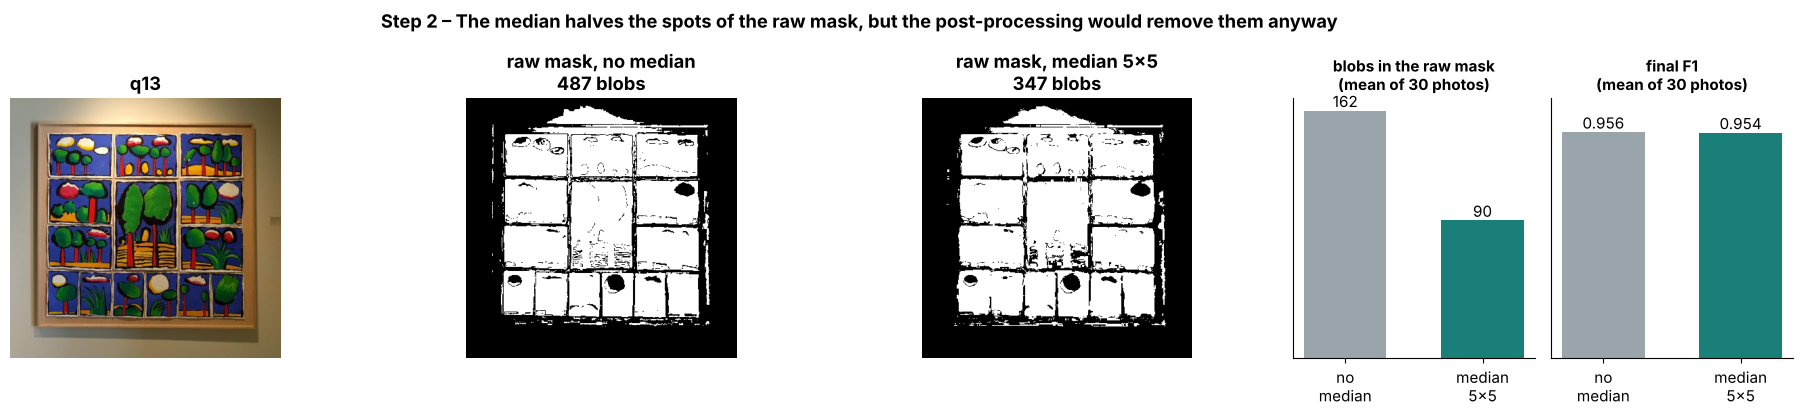

{'no median': '162 blobs in the raw mask, final F1 0.956', 'median': '90 blobs in the raw mask, final F1 0.954'}


In [8]:
def raw_and_final(img, median):
    """Raw and final mask on the 400 px copy, with or without the median filter on the small image."""
    sm = resize_max(img); sm = cv2.medianBlur(sm, 5) if median else sm
    lab = cv2.cvtColor(sm, cv2.COLOR_BGR2LAB).astype(np.float64)
    full_lab = cv2.cvtColor(cv2.medianBlur(img, 5) if median else img, cv2.COLOR_BGR2LAB)
    mu, cov, _ = robust_gaussian(full_lab[border_mask(*img.shape[:2], BORDER_PX)].astype(np.float64))
    ld = np.log1p(mahalanobis_map(lab, mu, cov)); raw = ld > otsu_threshold(ld)
    m = raw.astype(np.uint8)
    m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_CLOSE, struct_el(m.shape, 0.03)), cv2.MORPH_OPEN, struct_el(m.shape, 0.02))
    return raw, row_col_fill(fill_holes(largest_component(m)))


def n_blobs(m):
    """Number of painting blobs + number of wall blobs (1 + 1 for a perfect mask)."""
    return (cv2.connectedComponents(m.astype(np.uint8))[0] - 1) + (cv2.connectedComponents((~m).astype(np.uint8))[0] - 1)


med_stats = {}
for med in (False, True):
    blobs, f1s = [], []
    for im_, g in zip(IMGS, GTS):
        raw, fin = raw_and_final(im_, med)
        blobs.append(n_blobs(raw))
        f1s.append(prf(cv2.resize(fin.astype(np.uint8), g.shape[::-1], interpolation=cv2.INTER_NEAREST) > 0, g)[2])
    med_stats[med] = (np.mean(blobs), np.mean(f1s))

i = 13
raw0, _ = raw_and_final(IMGS[i], False); raw1, _ = raw_and_final(IMGS[i], True)
fig, axes = plt.subplots(1, 5, figsize=(19, 4.2), gridspec_kw=dict(width_ratios=[1, 1, 1, 0.55, 0.55]))
axes[0].imshow(rgb(resize_max(IMGS[i]))); axes[0].set_title(f"q{i}")
axes[1].imshow(raw0, cmap="gray"); axes[1].set_title(f"raw mask, no median\n{n_blobs(raw0)} blobs")
axes[2].imshow(raw1, cmap="gray"); axes[2].set_title(f"raw mask, median 5×5\n{n_blobs(raw1)} blobs")
for a in axes[:3]: a.axis("off")
for a, k, name, fmt in [(axes[3], 0, "blobs in the raw mask\n(mean of 30 photos)", "%.0f"), (axes[4], 1, "final F1\n(mean of 30 photos)", "%.3f")]:
    b = a.bar([0, 1], [med_stats[False][k], med_stats[True][k]], 0.6, color=[GREY, TEAL])
    a.bar_label(b, fmt=fmt); a.set_xticks([0, 1], ["no\nmedian", "median\n5×5"]); a.set_title(name, fontsize=11)
    a.set_yticks([])
axes[4].set_ylim(0, 1.1)
plt.suptitle("Step 2 – The median halves the spots of the raw mask, but the post-processing would remove them anyway",
             fontweight="bold")
plt.tight_layout(); savefig("2_median_effect"); plt.show()
print({("median" if k else "no median"): f"{v[0]:.0f} blobs in the raw mask, final F1 {v[1]:.3f}" for k, v in med_stats.items()})

## Step 3 – Convert to Lab

Lab separates **brightness** (L) from **colour** (a: green ↔ red, b: blue ↔ yellow; 128 = no colour in OpenCV).
This is exactly what we need: the light on a wall changes a lot from one side to the other (L), but the colour of the wall
(a, b) is almost constant. A painting, instead, usually has a different colour. Look at q9: the wall is much darker on
the left in L, but flat in a and b.

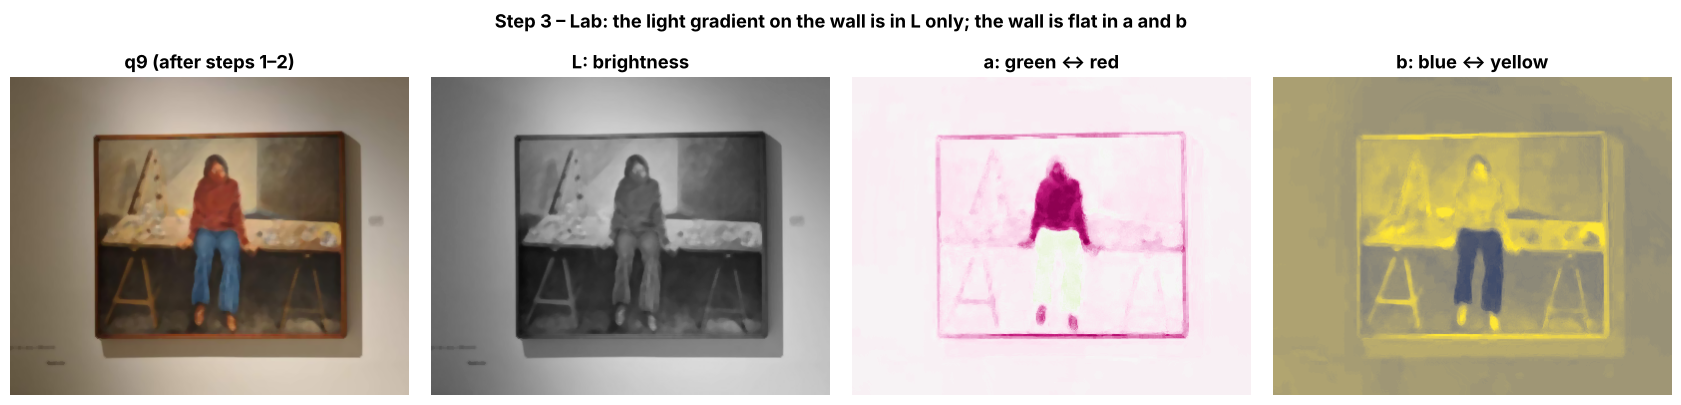

In [9]:
i = 9
lab9 = STEPS[i]["lab"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.9))
axes[0].imshow(rgb(STEPS[i]["small"])); axes[0].set_title(f"q{i} (after steps 1–2)")
axes[1].imshow(lab9[..., 0], cmap="gray", vmin=0, vmax=255); axes[1].set_title("L: brightness")
for a, c, name, cmap in [(axes[2], 1, "a: green ↔ red", "PiYG_r"), (axes[3], 2, "b: blue ↔ yellow", "cividis")]:
    a.imshow(lab9[..., c], cmap=cmap, vmin=128 - 35, vmax=128 + 35); a.set_title(name)
for a in axes: a.axis("off")
plt.suptitle("Step 3 – Lab: the light gradient on the wall is in L only; the wall is flat in a and b", fontweight="bold", y=1.03)
plt.tight_layout(); savefig("3_lab"); plt.show()

## Step 4 – The 15-px border strip = wall samples

We take the pixels of a **15-px strip along the four borders** of the photo, at **full resolution** (with the same 5×5
median), and convert them to Lab. Thanks to the organisers' guarantee, these pixels are always wall.

**Why 15 px and at full resolution** (the change made in `c1-week2-15px.ipynb`): the previous version used a strip of
**4% of the shorter side** of the image. That is a *relative* size: ~22 px on a 550 px photo, but **~70–76 px on a
1900 px photo**. In three large QSD2 photos (11, 16, 23) that strip already went into the frame. With a fixed 15 px at full
resolution, the strip is always inside the guaranteed wall, whatever the size of the photo.

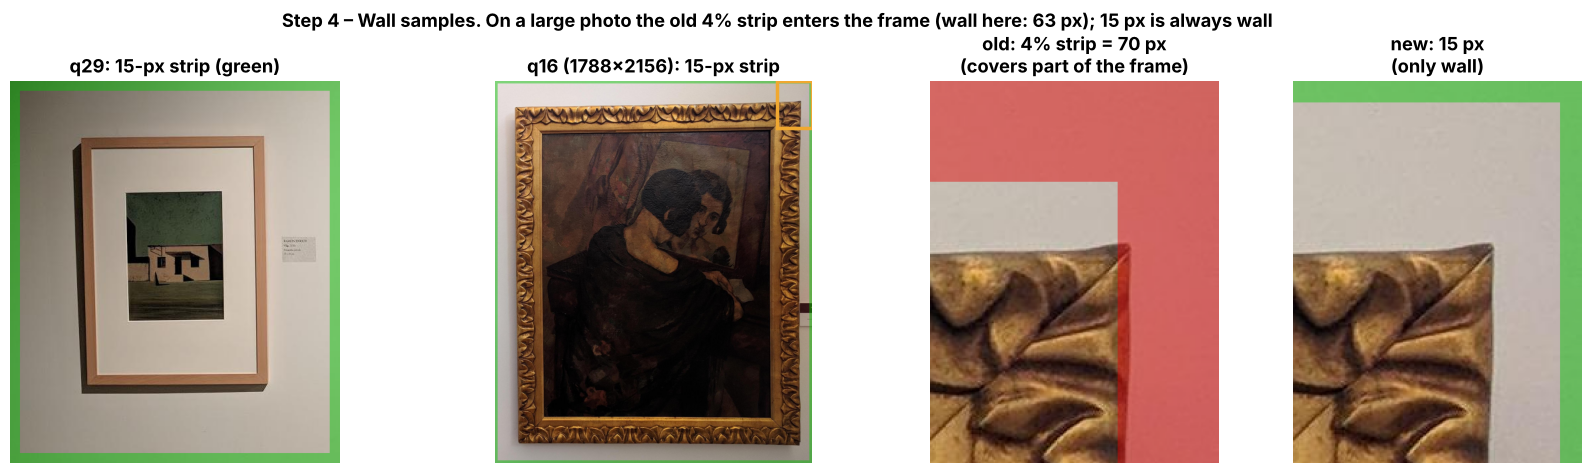

In [10]:
def strip_overlay(img, t, colour):
    out = img.copy(); bm = border_mask(*img.shape[:2], t)
    out[bm] = (0.55 * out[bm] + 0.45 * np.array(colour)).astype(np.uint8)
    return out


i = 16
img = IMGS[i]; H, W = img.shape[:2]
t_old = int(round(0.04 * min(resize_max(img).shape[:2])) * H / resize_max(img).shape[0])   # 4% strip in full-res pixels
rows_ = np.where(GTS[i].any(1))[0]
right_gap = np.array([W - 1 - np.where(GTS[i][y])[0].max() for y in rows_])
yc = rows_[np.argmin(right_gap)]                                     # row where the painting is closest to the border
xs_ = slice(W - 200, W); ys_ = slice(max(0, yc - 150), min(H, yc + 150))
fig, axes = plt.subplots(1, 4, figsize=(17, 4.8), gridspec_kw=dict(width_ratios=[1, 1, 0.75, 0.75]))
axes[0].imshow(rgb(strip_overlay(IMGS[MAIN], BORDER_PX, (0, 200, 0)))); axes[0].set_title(f"q{MAIN}: 15-px strip (green)")
axes[1].imshow(rgb(strip_overlay(img, BORDER_PX, (0, 200, 0))))
axes[1].add_patch(Rectangle((xs_.start, ys_.start), 200, ys_.stop - ys_.start, fill=False, ec=ORANGE, lw=2.5))
axes[1].set_title(f"q{i} ({W}×{H}): 15-px strip")
axes[2].imshow(rgb(strip_overlay(img, t_old, (0, 0, 230))[ys_, xs_])); axes[2].set_title(f"old: 4% strip = {t_old} px\n(covers part of the frame)")
axes[3].imshow(rgb(strip_overlay(img, BORDER_PX, (0, 200, 0))[ys_, xs_])); axes[3].set_title("new: 15 px\n(only wall)")
for a in axes: a.axis("off")
plt.suptitle(f"Step 4 – Wall samples. On a large photo the old 4% strip enters the frame "
             f"(wall here: {gaps[i]} px); 15 px is always wall", fontweight="bold")
plt.tight_layout(); savefig("4_strip"); plt.show()

**What happens in the test set, where there may be only 15 px of wall?** We simulate it: we crop every QSD2 photo so that
only X px of wall are left around the painting, and compute the masks with the old 4% strip and with the 15-px strip.

In [11]:
def mask_old_strip(img):
    """Same method but with the old wall strip: 4% of the shorter side of the 400 px copy."""
    small = cv2.medianBlur(resize_max(img), 5)
    lab = cv2.cvtColor(small, cv2.COLOR_BGR2LAB).astype(np.float64)
    t = max(2, int(round(0.04 * min(lab.shape[:2]))))
    mu, cov, _ = robust_gaussian(lab[border_mask(*lab.shape[:2], t)])
    ld = np.log1p(mahalanobis_map(lab, mu, cov))
    m = (ld > otsu_threshold(ld)).astype(np.uint8)
    m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_CLOSE, struct_el(m.shape, 0.03)), cv2.MORPH_OPEN, struct_el(m.shape, 0.02))
    m = row_col_fill(fill_holes(largest_component(m)))
    m = m if m.any() else np.ones_like(m)
    return cv2.resize(m.astype(np.uint8), img.shape[1::-1], interpolation=cv2.INTER_NEAREST).astype(bool)


def crop_wall(img, gt, gap):
    ys, xs = np.where(gt); H, W = gt.shape
    y0, y1, x0, x1 = max(0, ys.min() - gap), min(H, ys.max() + 1 + gap), max(0, xs.min() - gap), min(W, xs.max() + 1 + gap)
    return img[y0:y1, x0:x1], gt[y0:y1, x0:x1]


t0 = time.time()
GAPS = [60, 40, 25, 15]
sim = {"old 4% strip": [], "15-px strip": []}
for gap in GAPS:
    f_old, f_new = [], []
    for im_, g in zip(IMGS, GTS):
        ci, cg = crop_wall(im_, g, gap)
        f_old.append(prf(mask_old_strip(ci), cg)[2]); f_new.append(prf(run_steps(ci)["mask"], cg)[2])
    sim["old 4% strip"].append(f_old); sim["15-px strip"].append(f_new)
print(f"simulation done in {time.time() - t0:.0f}s")
for name, v in sim.items():
    print(f"{name:13s}", "  ".join(f"{g} px: F1 {np.mean(f):.3f} ({sum(x < 0.8 for x in f)} photos < 0.8)" for g, f in zip(GAPS, v)))

simulation done in 9s
old 4% strip  60 px: F1 0.957 (1 photos < 0.8)  40 px: F1 0.936 (3 photos < 0.8)  25 px: F1 0.877 (8 photos < 0.8)  15 px: F1 0.868 (9 photos < 0.8)
15-px strip   60 px: F1 0.957 (1 photos < 0.8)  40 px: F1 0.958 (1 photos < 0.8)  25 px: F1 0.943 (2 photos < 0.8)  15 px: F1 0.936 (2 photos < 0.8)


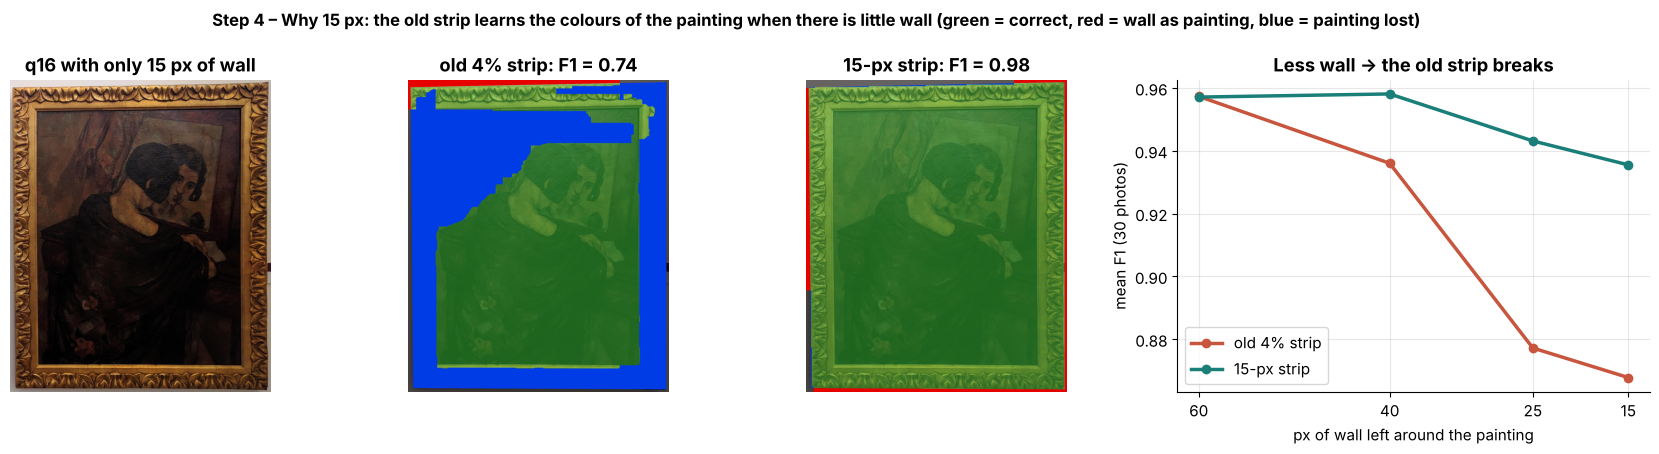

In [12]:
i = 16
ci, cg = crop_wall(IMGS[i], GTS[i], 15)
m_old, m_new = mask_old_strip(ci), run_steps(ci)["mask"]
fig = plt.figure(figsize=(17, 4.6))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 1.5])
ax = [fig.add_subplot(gs[k]) for k in range(4)]
ax[0].imshow(rgb(ci)); ax[0].set_title(f"q{i} with only 15 px of wall")
ax[1].imshow(rgb(error_overlay(ci, m_old, cg))); ax[1].set_title(f"old 4% strip: F1 = {prf(m_old, cg)[2]:.2f}")
ax[2].imshow(rgb(error_overlay(ci, m_new, cg))); ax[2].set_title(f"15-px strip: F1 = {prf(m_new, cg)[2]:.2f}")
for a in ax[:3]: a.axis("off")
for name, col in [("old 4% strip", RED), ("15-px strip", TEAL)]:
    ax[3].plot(GAPS, [np.mean(f) for f in sim[name]], "o-", color=col, lw=2.5, label=name)
ax[3].invert_xaxis(); ax[3].set_xticks(GAPS); ax[3].set_xlabel("px of wall left around the painting")
ax[3].set_ylabel("mean F1 (30 photos)"); ax[3].legend(); ax[3].grid(alpha=0.3); ax[3].set_title("Less wall → the old strip breaks")
plt.suptitle("Step 4 – Why 15 px: the old strip learns the colours of the painting when there is little wall "
             "(green = correct, red = wall as painting, blue = painting lost)", fontweight="bold", fontsize=12)
plt.tight_layout(); savefig("4_thin_wall"); plt.show()

## Step 5 – Robust Gaussian model of the wall

We describe the wall colour with a **3D Gaussian** in Lab:
- the **mean** μ: the typical wall colour;
- the **covariance** Σ: how much the wall varies in each direction (and how L, a, b vary together).

**Robust estimate:** even inside the guaranteed wall there can be darker corners (vignetting of the camera), a shadow, a
plug or the edge of a label. We compute the distance of every strip pixel to the **median** colour and keep the **80%
closest** (the dominant colour = the wall). The ellipses show the model (2σ): the wall is **long in L** (the light
changes) and **very thin in a and b** (the colour does not).

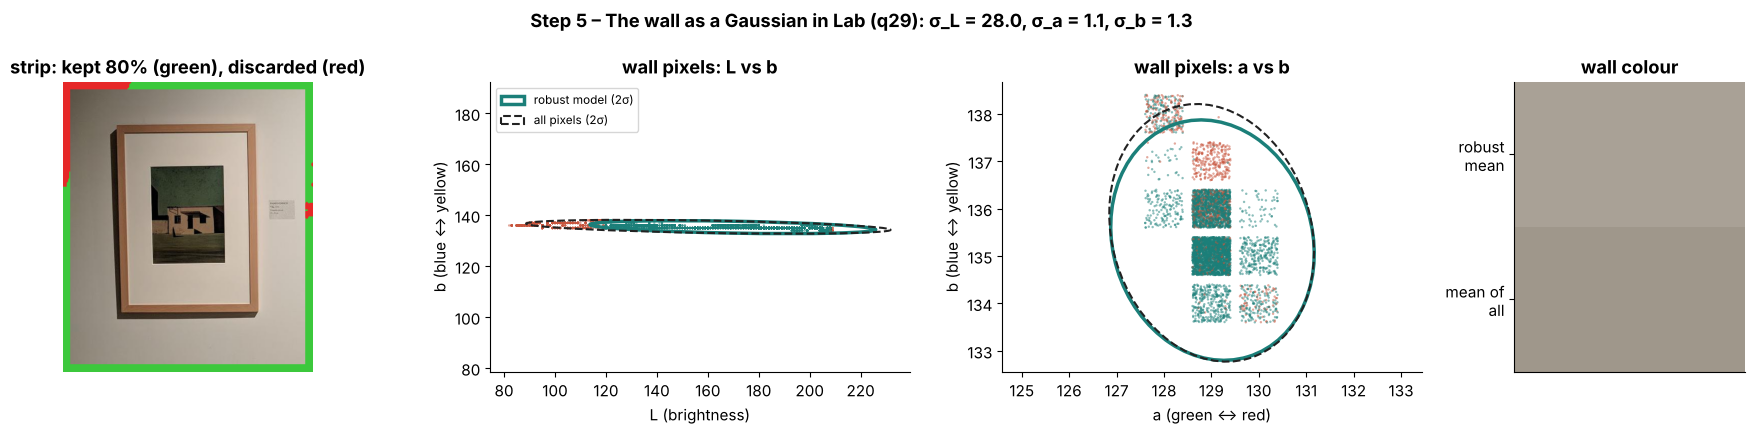

In [13]:
def cov_ellipse(ax, mu2, cov2, k=2, **kw):
    vals, vecs = np.linalg.eigh(cov2)
    ang = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    ax.add_patch(Ellipse(mu2, 2 * k * np.sqrt(vals[1]), 2 * k * np.sqrt(vals[0]), angle=ang, fill=False, **kw))


P, kept = S["P"], S["kept"]
mu_all, cov_all = P.mean(0), np.cov(P.T) + np.eye(3)
rng = np.random.default_rng(0)
sub = rng.choice(len(P), min(len(P), 6000), replace=False)
img = IMGS[MAIN]; H, W = img.shape[:2]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4), gridspec_kw=dict(width_ratios=[1, 1, 1, 0.55]))
vis = img.copy(); bm = border_mask(H, W, BORDER_PX)
cols = np.where(kept[:, None], [60, 200, 60], [40, 40, 230])
vis[bm] = cols.astype(np.uint8)
axes[0].imshow(rgb(vis)); axes[0].set_title("strip: kept 80% (green), discarded (red)"); axes[0].axis("off")
for a, (cx, cy, nx, ny) in zip(axes[1:3], [(0, 2, "L (brightness)", "b (blue ↔ yellow)"), (1, 2, "a (green ↔ red)", "b (blue ↔ yellow)")]):
    jit = rng.uniform(-0.4, 0.4, (len(sub), 2)) if cx == 1 else 0   # a, b are integers: jitter so the points do not overlap
    a.scatter(P[sub, cx] + (jit[:, 0] if cx == 1 else 0), P[sub, cy] + (jit[:, 1] if cx == 1 else 0), s=3,
              c=np.where(kept[sub], TEAL, RED), alpha=0.5, lw=0)
    cov_ellipse(a, S["mu"][[cx, cy]], S["cov"][np.ix_([cx, cy], [cx, cy])], ec=TEAL, lw=2.5, label="robust model (2σ)")
    cov_ellipse(a, mu_all[[cx, cy]], cov_all[np.ix_([cx, cy], [cx, cy])], ec=INK, lw=1.5, ls="--", label="all pixels (2σ)")
    a.set_xlabel(nx); a.set_ylabel(ny); a.set_aspect("equal", adjustable="datalim")
axes[1].legend(fontsize=8.5, loc="upper left"); axes[1].set_title("wall pixels: L vs b"); axes[2].set_title("wall pixels: a vs b")
sw = np.zeros((2, 1, 3), np.uint8); sw[0, 0], sw[1, 0] = S["mu"].round(), mu_all.round()
axes[3].imshow(rgb(cv2.cvtColor(sw, cv2.COLOR_LAB2BGR)), aspect="auto"); axes[3].set_xticks([])
axes[3].set_yticks([0, 1], ["robust\nmean", "mean of\nall"]); axes[3].set_title("wall colour")
plt.suptitle(f"Step 5 – The wall as a Gaussian in Lab (q{MAIN}): σ_L = {np.sqrt(S['cov'][0, 0]):.1f}, "
             f"σ_a = {np.sqrt(S['cov'][1, 1]):.1f}, σ_b = {np.sqrt(S['cov'][2, 2]):.1f}", fontweight="bold")
plt.tight_layout(); savefig("5_gaussian"); plt.show()

With the 15-px strip the discarded 20% are mostly the darker corners of the wall (vignetting). The robust estimate barely
changes the mean F1 (0.955 without it, 0.954 with it; ablation of the main notebook): it is a safety net for strips with
something that is not wall.

## Step 6 – Mahalanobis distance

For every pixel of the 400 px image we compute how far its colour is from the wall model:

$$d_M(x) = \sqrt{(x-\mu)^\top \Sigma^{-1} (x-\mu)}$$

It is a distance **measured in units of the wall's own variation** ("how many σ away"). In a direction where the wall
varies a lot (L), a big change counts little; in a direction where the wall almost never varies (a, b), a small change
counts a lot. The Euclidean distance treats all directions the same.

Example with the real model of q29: two colours at the **same Euclidean distance** (25) from the wall mean, one brighter
(like the wall under more light) and one more yellow (like the wooden frame):

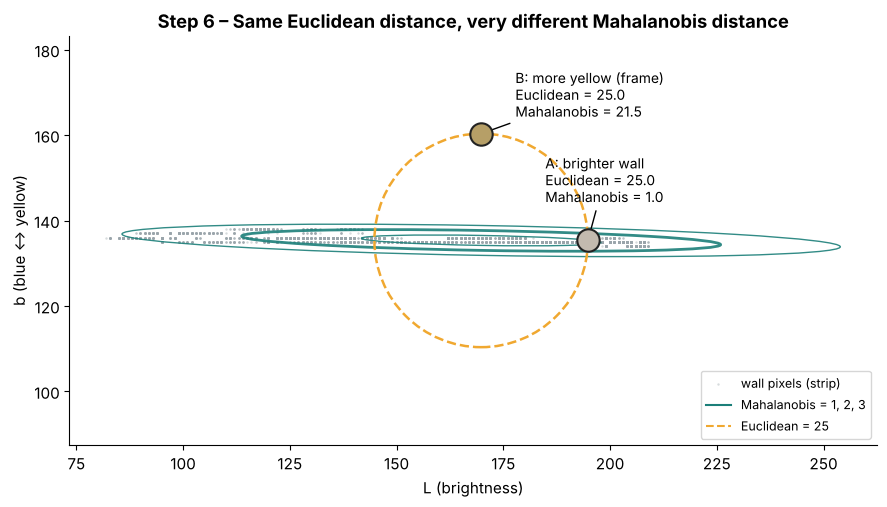

In [14]:
mu, cov = S["mu"], S["cov"]
A = mu + np.array([25, 0, 0]); B = mu + np.array([0, 0, 25])
dA, dB = [float(np.sqrt((x - mu) @ np.linalg.inv(cov) @ (x - mu))) for x in (A, B)]
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.scatter(P[sub, 0], P[sub, 2], s=3, c=GREY, alpha=0.4, lw=0, label="wall pixels (strip)")
for k in (1, 2, 3):
    cov_ellipse(ax, mu[[0, 2]], cov[np.ix_([0, 2], [0, 2])], k=k, ec=TEAL, lw=2 if k == 2 else 1, alpha=0.9)
ax.add_patch(plt.Circle(mu[[0, 2]], 25, fill=False, ec=ORANGE, ls="--", lw=1.8))
for x, d, name, off in [(A, dA, "A: brighter wall", (-10, 9)), (B, dB, "B: more yellow (frame)", (8, 4))]:
    sw = cv2.cvtColor(np.uint8([[x.clip(0, 255)]]), cv2.COLOR_LAB2RGB)[0, 0] / 255
    ax.scatter(x[0], x[2], s=260, color=sw, ec=INK, lw=1.5, zorder=5)
    ax.annotate(f"{name}\nEuclidean = 25.0\nMahalanobis = {d:.1f}", (x[0], x[2]), (x[0] + off[0], x[2] + off[1]),
                fontsize=10, arrowprops=dict(arrowstyle="->"))
ax.plot([], [], color=TEAL, label="Mahalanobis = 1, 2, 3"); ax.plot([], [], color=ORANGE, ls="--", label="Euclidean = 25")
ax.set_xlabel("L (brightness)"); ax.set_ylabel("b (blue ↔ yellow)"); ax.set_aspect("equal", adjustable="datalim")
ax.legend(loc="lower right", fontsize=9); ax.set_title("Step 6 – Same Euclidean distance, very different Mahalanobis distance")
plt.tight_layout(); savefig("6_mahalanobis_idea"); plt.show()

On the whole image: with the Euclidean distance the **light gradient of the wall** looks like "not wall"; with Mahalanobis
the wall is uniformly dark (close to the model) and the painting and frame stand out.

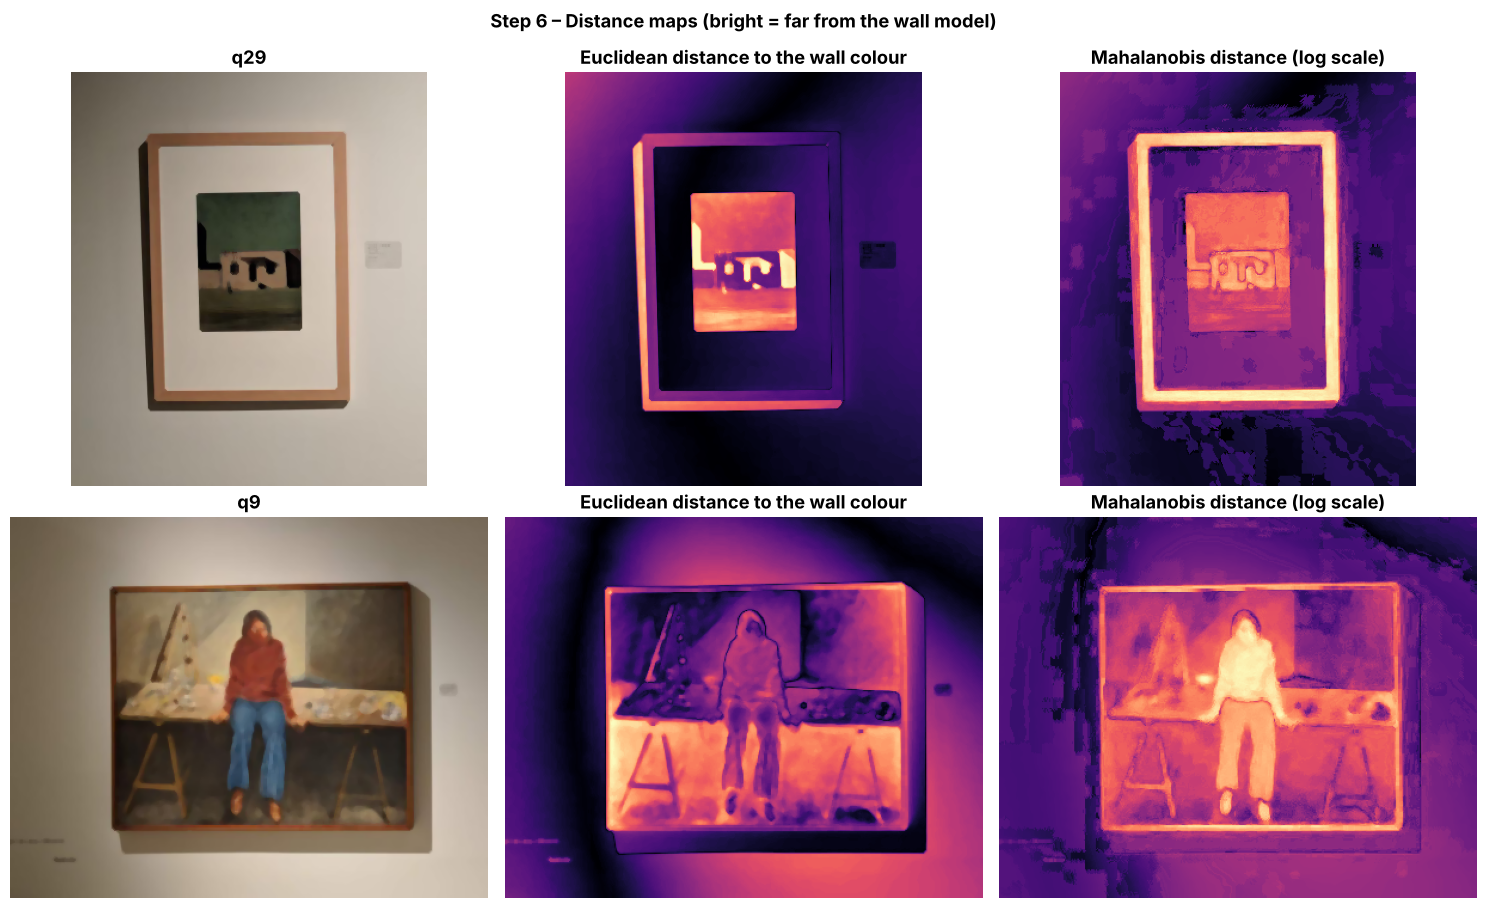

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9.4))
for r, i in enumerate([MAIN, 9]):
    st = STEPS[i]
    axes[r, 0].imshow(rgb(st["small"])); axes[r, 0].set_title(f"q{i}")
    axes[r, 1].imshow(st["eucl"], cmap="magma"); axes[r, 1].set_title("Euclidean distance to the wall colour")
    axes[r, 2].imshow(st["ld"], cmap="magma"); axes[r, 2].set_title("Mahalanobis distance (log scale)")
for a in axes.ravel(): a.axis("off")
plt.suptitle("Step 6 – Distance maps (bright = far from the wall model)", fontweight="bold")
plt.tight_layout(); savefig("6_maps"); plt.show()

## Step 7 – log + Otsu threshold: painting or wall?

Now we need a threshold: distance above → painting, below → wall. A fixed threshold does not work for every photo (method M1
of the main notebook: F1 0.81–0.87), so we let **Otsu** choose it for each image.

- **log(1 + d):** the distances have a very long tail (the painting can be 100σ away, the wall is 0–3σ). The log compresses
  the tail so the histogram shows two clear groups.
- **Otsu:** tries every threshold and keeps the one that best separates the histogram into two groups (maximum
  *between-class variance* = the two groups are as far apart and as compact as possible). No parameter to tune.

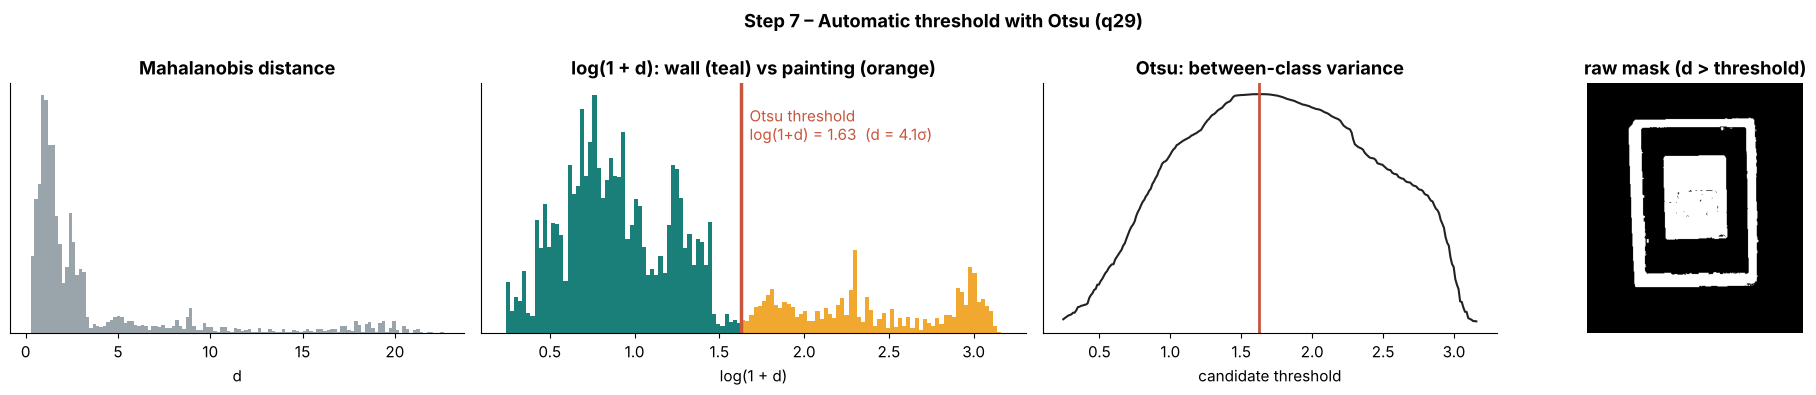

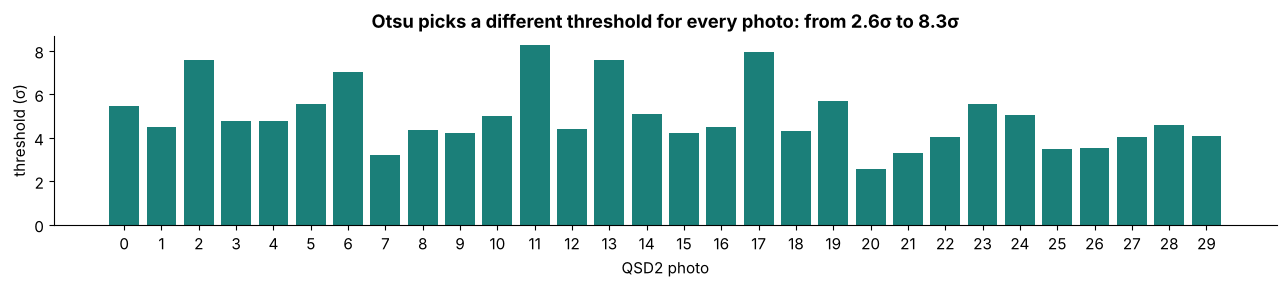

In [16]:
t, centres, between = otsu_threshold(S["ld"], return_curve=True)
fig, axes = plt.subplots(1, 4, figsize=(19, 4), gridspec_kw=dict(width_ratios=[1, 1.2, 1, 0.8]))
axes[0].hist(S["maha"].ravel(), 120, color=GREY); axes[0].set_title("Mahalanobis distance"); axes[0].set_xlabel("d")
axes[0].set_yticks([])
n, bins, patches = axes[1].hist(S["ld"].ravel(), 120)
for p_, c_ in zip(patches, (bins[:-1] + bins[1:]) / 2):
    p_.set_facecolor(TEAL if c_ <= t else ORANGE)
axes[1].axvline(t, color=RED, lw=2.5); axes[1].set_yticks([]); axes[1].set_xlabel("log(1 + d)")
axes[1].text(t, n.max() * 0.95, f"  Otsu threshold\n  log(1+d) = {t:.2f}  (d = {np.expm1(t):.1f}σ)", color=RED, va="top")
axes[1].set_title("log(1 + d): wall (teal) vs painting (orange)")
axes[2].plot(centres, between, color=INK); axes[2].axvline(t, color=RED, lw=2); axes[2].set_yticks([])
axes[2].set_title("Otsu: between-class variance"); axes[2].set_xlabel("candidate threshold")
axes[3].imshow(S["raw"], cmap="gray"); axes[3].set_title("raw mask (d > threshold)"); axes[3].axis("off")
plt.suptitle(f"Step 7 – Automatic threshold with Otsu (q{MAIN})", fontweight="bold")
plt.tight_layout(); savefig("7_otsu"); plt.show()

thr = np.array([np.expm1(st["thr"]) for st in STEPS])
fig, ax = plt.subplots(figsize=(13, 3))
ax.bar(range(30), thr, color=TEAL); ax.set_xticks(range(30)); ax.set_xlabel("QSD2 photo"); ax.set_ylabel("threshold (σ)")
ax.set_title(f"Otsu picks a different threshold for every photo: from {thr.min():.1f}σ to {thr.max():.1f}σ")
plt.tight_layout(); savefig("7_thresholds"); plt.show()

## Step 8 – Post-processing of the binary mask

The raw mask has typical errors: isolated pixels on the wall (a label, a plug, a stain), small cracks inside the
painting, and **holes** where the painting has the colour of the wall (a white passe-partout, a light sky). We fix them
**only with operations on the mask** (no image contours):

1. **closing** (dilate, then erode) with a square of 3% of the side: closes thin cracks and small gaps;
2. **opening** (erode, then dilate) with a square of 2% of the side: removes small isolated spots;
3. **largest connected component**: keep only the biggest blob (the painting), drop labels and other objects;
4. **fill holes**: background pixels that cannot be reached from the border of the image are inside the painting →
   painting (flood fill from a corner);
5. **row / column fill**: in every row, fill from the first to the last painting pixel; the same in every column; keep the
   intersection. It fills the "bays": wall-coloured areas inside the painting that are **connected to the outside** through
   an opening in the frame, so step 4 cannot fill them (they are not closed holes). Only the rows / columns of the opening
   itself stay empty.

First on a toy mask, so each operation is easy to see (green = pixels added, red = pixels removed by that step):

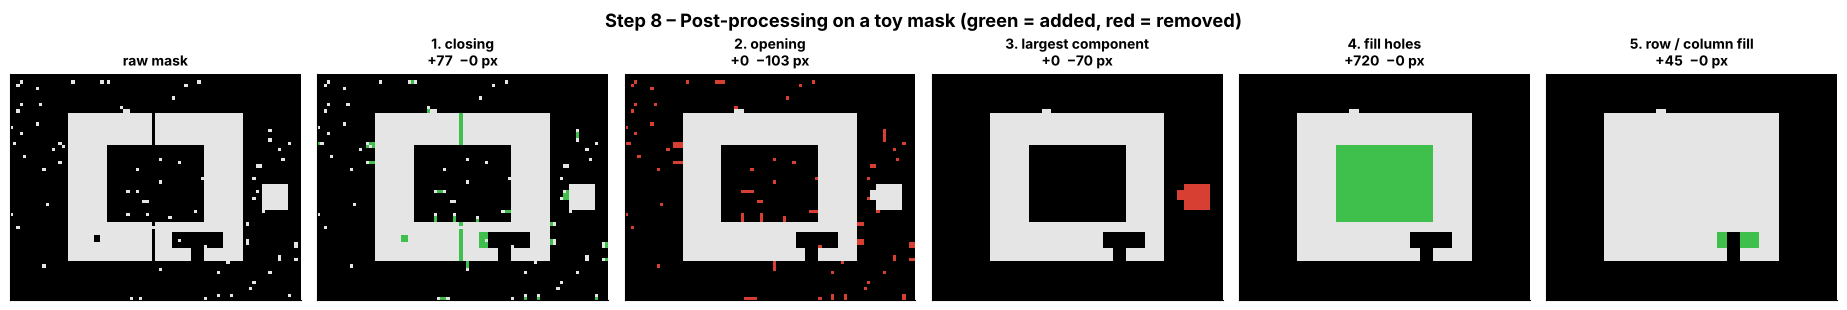

In [17]:
toy = np.zeros((70, 90), np.uint8)
toy[12:58, 18:72] = 1                       # the painting
toy[22:46, 30:60] = 0                       # a wall-coloured area inside (passe-partout / sky): a hole
toy[12:58, 44:45] = 0                       # a thin crack
toy[49:54, 50:66] = 0                       # a "bay": a wall-coloured area inside the painting...
toy[54:58, 56:60] = 0                       # ...connected to the outside through a 4-px opening in the frame
toy[34:42, 78:86] = 1                       # a label on the wall
toy[rng.random(toy.shape) < 0.015] = 1      # isolated noisy pixels
toy[50:52, 26:28] = 0                       # a tiny gap


def diff_image(prev, cur):
    out = np.zeros(cur.shape + (3,)); out[cur] = 0.9
    out[cur & ~prev] = (0.25, 0.75, 0.3); out[prev & ~cur] = (0.85, 0.25, 0.2)
    return out


def plot_sequence(seq, title, name, toy_mode=False):
    fig, axes = plt.subplots(1, len(seq), figsize=(3.1 * len(seq), 3.3 if toy_mode else 4))
    prev = seq[0][1]
    for a, (lbl, m) in zip(axes, seq):
        a.imshow(diff_image(prev, m) if lbl != "raw mask" else diff_image(m, m), interpolation="nearest")
        a.set_title(f"{lbl}\n+{np.sum(m & ~prev)}  −{np.sum(prev & ~m)} px" if lbl != "raw mask" else lbl, fontsize=10)
        a.set_xticks([]); a.set_yticks([]); prev = m
    plt.suptitle(title, fontweight="bold"); plt.tight_layout(); savefig(name); plt.show()


# the toy mask is small, so we use bigger structuring elements than the 2–3% of the real method
def post_sequence_toy(raw):
    c = cv2.morphologyEx(raw, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8)).astype(bool)
    o = cv2.morphologyEx(c.astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)).astype(bool)
    l = largest_component(o); hf = fill_holes(l); rc = row_col_fill(hf)
    return [("raw mask", raw.astype(bool)), ("1. closing", c), ("2. opening", o), ("3. largest component", l),
            ("4. fill holes", hf), ("5. row / column fill", rc)]


plot_sequence(post_sequence_toy(toy), "Step 8 – Post-processing on a toy mask (green = added, red = removed)", "8_post_toy", True)

The same on two real photos:
- **q29:** the white passe-partout has the colour of the wall, so the frame and the painting are two separate blobs.
  Step 3 keeps only the biggest one (the frame) and deletes the painting (red), but step 4 brings back everything inside
  the frame (painting + passe-partout), because it is a closed hole.
- **q17:** the light-blue area at the top left is close to the wall colour and is connected to the outside through the
  gap between the sheets at the top, so it is not a closed hole and step 4 cannot fill it. The row / column fill does
  (only the columns of the gap stay open).

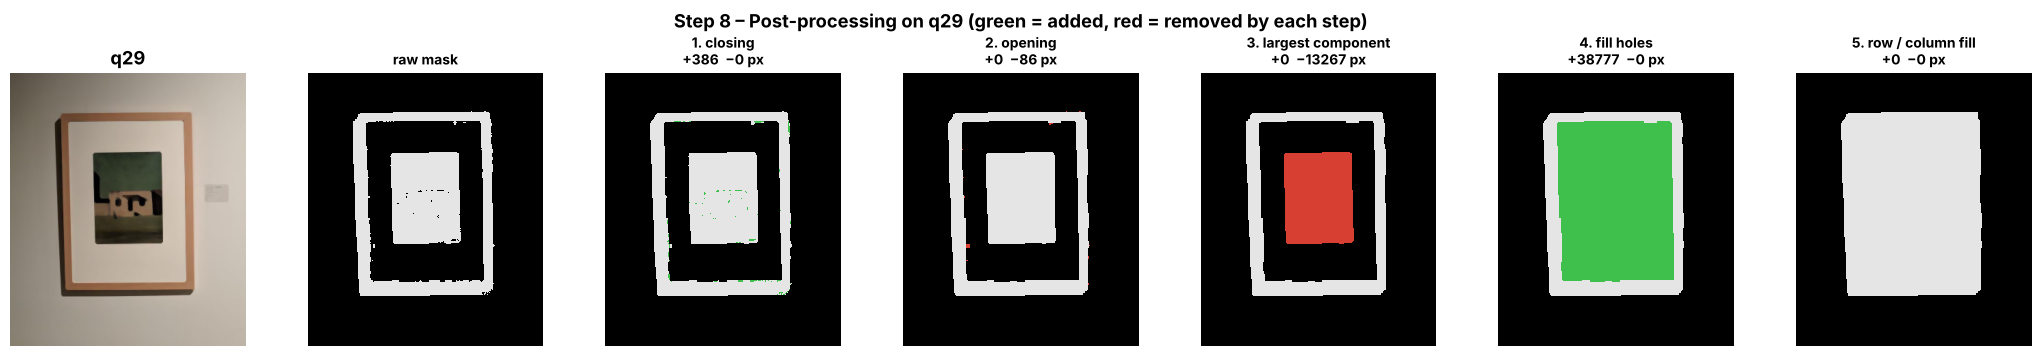

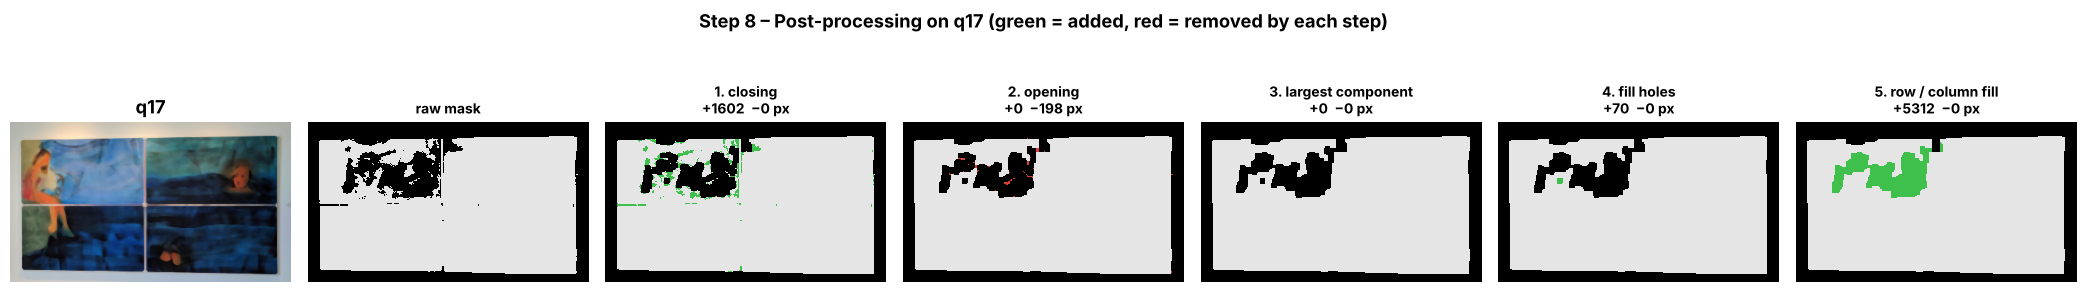

In [18]:
for i in [MAIN, 17]:
    st = STEPS[i]
    seq = [("raw mask", st["raw"]), ("1. closing", st["close"]), ("2. opening", st["open"]),
           ("3. largest component", st["largest"]), ("4. fill holes", st["holes"]), ("5. row / column fill", st["rowcol"])]
    fig, axes = plt.subplots(1, 7, figsize=(21, 3.6))
    axes[0].imshow(rgb(st["small"])); axes[0].set_title(f"q{i}"); axes[0].axis("off")
    prev = seq[0][1]
    for a, (lbl, m) in zip(axes[1:], seq):
        a.imshow(diff_image(prev, m) if lbl != "raw mask" else diff_image(m, m), interpolation="nearest")
        a.set_title(f"{lbl}\n+{np.sum(m & ~prev)}  −{np.sum(prev & ~m)} px" if lbl != "raw mask" else lbl, fontsize=10)
        a.axis("off"); prev = m
    plt.suptitle(f"Step 8 – Post-processing on q{i} (green = added, red = removed by each step)", fontweight="bold")
    plt.tight_layout(); savefig(f"8_post_q{i}"); plt.show()

**How much does each step help?** Precision / recall / F1 over the 30 photos after each step:

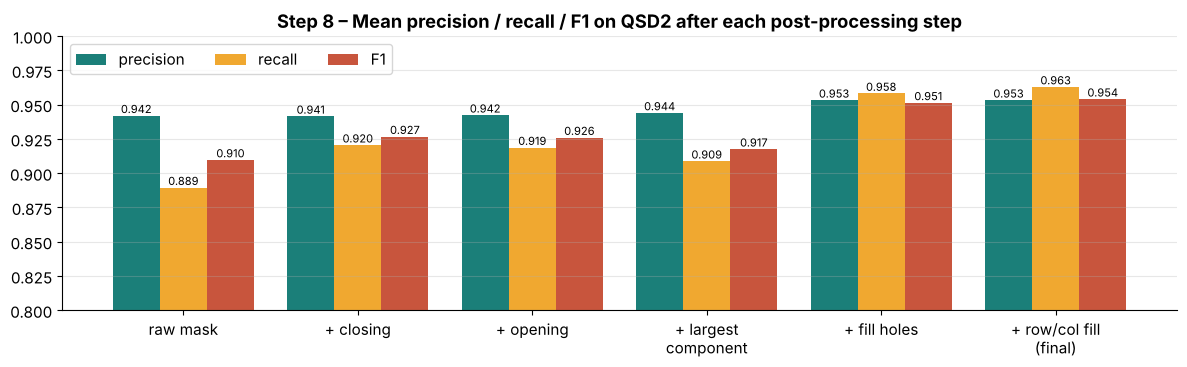

In [19]:
order = ["raw", "close", "open", "largest", "holes", "rowcol"]
labels = ["raw mask", "+ closing", "+ opening", "+ largest\ncomponent", "+ fill holes", "+ row/col fill\n(final)"]
res = np.array([[prf(cv2.resize(st[k].astype(np.uint8), g.shape[::-1], interpolation=cv2.INTER_NEAREST) > 0, g)
                 for st, g in zip(STEPS, GTS)] for k in order])          # steps × photos × (P, R, F1)
fig, ax = plt.subplots(figsize=(12, 3.8))
for j, (name, col) in enumerate([("precision", TEAL), ("recall", ORANGE), ("F1", RED)]):
    bars = ax.bar(np.arange(len(order)) + (j - 1) * 0.27, res[:, :, j].mean(1), 0.27, color=col, label=name)
    ax.bar_label(bars, fmt="%.3f", fontsize=8)
ax.set_xticks(range(len(order)), labels); ax.set_ylim(0.8, 1.0); ax.legend(ncol=3, loc="upper left"); ax.grid(axis="y", alpha=0.3)
ax.set_title("Step 8 – Mean precision / recall / F1 on QSD2 after each post-processing step")
plt.tight_layout(); savefig("8_ablation"); plt.show()

## Step 9 – Back to full size and crop the bounding box

The 400 px mask is enlarged to the original size (nearest neighbour, so it stays binary 0 / 1). This is the `.png` we
submit for QST2. For retrieval (Task 5) we crop the **bounding box** of the mask: the painting with its frame, aligned like
the BBDD images.

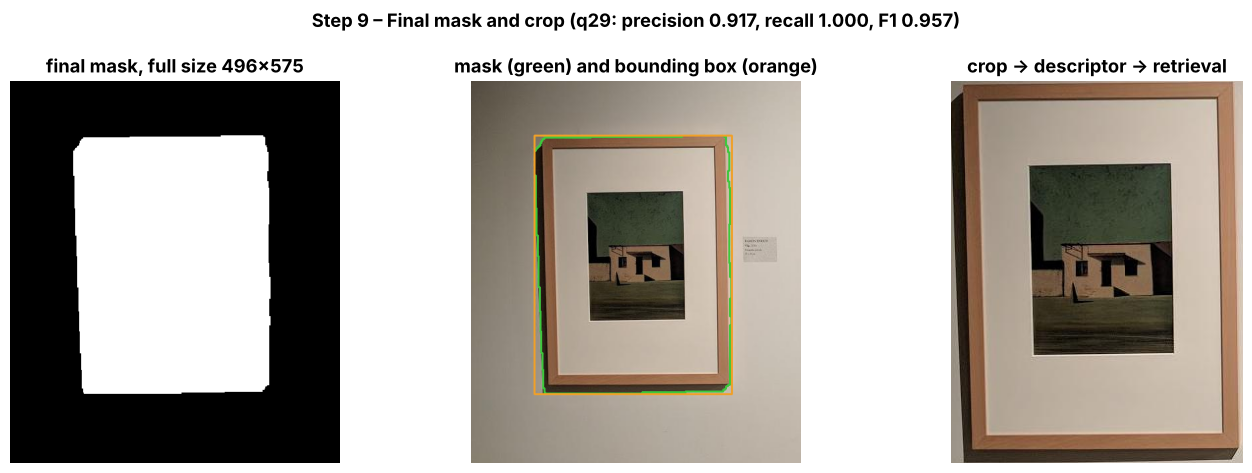

In [20]:
img = IMGS[MAIN]; m = S["mask"]
x, y, w_, h_ = cv2.boundingRect(m.astype(np.uint8))
cont, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
vis = img.copy(); cv2.drawContours(vis, cont, -1, (60, 200, 60), max(2, img.shape[0] // 200))
cv2.rectangle(vis, (x, y), (x + w_, y + h_), (40, 160, 240), max(2, img.shape[0] // 300))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
axes[0].imshow(m, cmap="gray"); axes[0].set_title(f"final mask, full size {img.shape[1]}×{img.shape[0]}")
axes[1].imshow(rgb(vis)); axes[1].set_title("mask (green) and bounding box (orange)")
axes[2].imshow(rgb(img[y:y + h_, x:x + w_])); axes[2].set_title("crop → descriptor → retrieval")
for a in axes: a.axis("off")
p_, r_, f_ = prf(m, GTS[MAIN])
plt.suptitle(f"Step 9 – Final mask and crop (q{MAIN}: precision {p_:.3f}, recall {r_:.3f}, F1 {f_:.3f})", fontweight="bold")
plt.tight_layout(); savefig("9_crop"); plt.show()

## Result on all of QSD2

Every mask compared with its ground truth: **green** = painting correctly kept, **red** = wall taken as painting (false
positive), **blue** = painting lost (false negative).

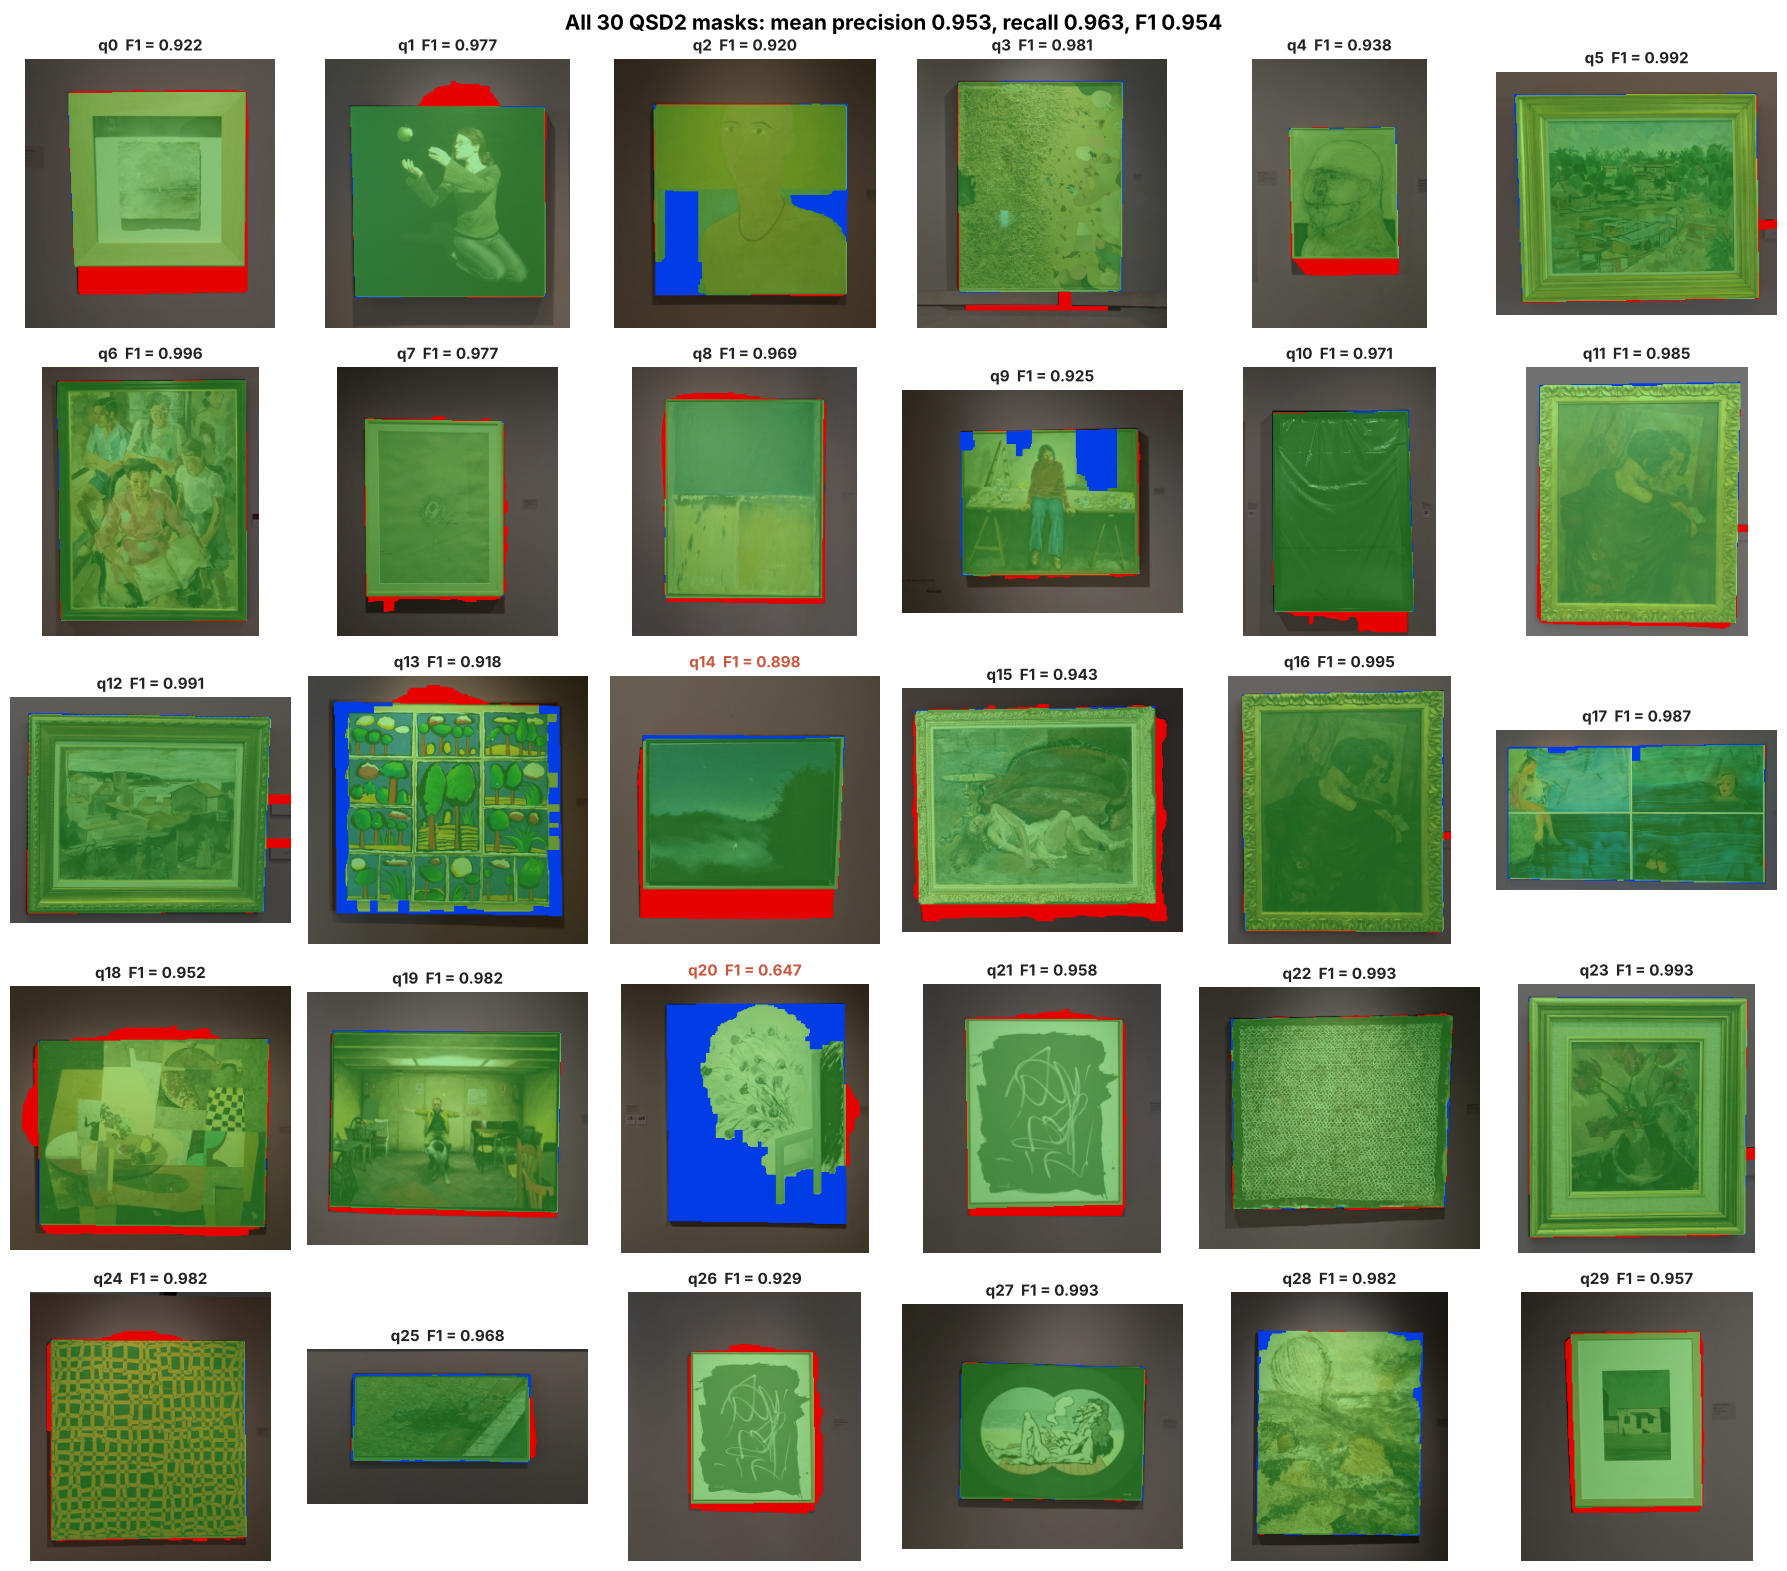

photos with F1 < 0.9: ['q14 (0.90)', 'q20 (0.65)']


In [21]:
R = np.array([prf(st["mask"], g) for st, g in zip(STEPS, GTS)])
fig, axes = plt.subplots(5, 6, figsize=(18, 16))
for i, a in enumerate(axes.ravel()):
    sm = resize_max(IMGS[i], 300); sz = sm.shape[1::-1]
    pm = cv2.resize(STEPS[i]["mask"].astype(np.uint8), sz, interpolation=cv2.INTER_NEAREST) > 0
    gm = cv2.resize(GTS[i].astype(np.uint8), sz, interpolation=cv2.INTER_NEAREST) > 0
    a.imshow(rgb(error_overlay(sm, pm, gm))); a.axis("off")
    a.set_title(f"q{i}  F1 = {R[i, 2]:.3f}", color=RED if R[i, 2] < 0.9 else INK, fontsize=11)
plt.suptitle(f"All 30 QSD2 masks: mean precision {R[:, 0].mean():.3f}, recall {R[:, 1].mean():.3f}, F1 {R[:, 2].mean():.3f}",
             fontweight="bold", fontsize=15)
plt.tight_layout(); savefig("10_all_masks"); plt.show()
print("photos with F1 < 0.9:", [f"q{i} ({R[i, 2]:.2f})" for i in np.where(R[:, 2] < 0.9)[0]])

## Summary

| Step | What it does | What it fixes |
|---|---|---|
| 1. Downscale to 400 px | ~30× fewer pixels on large photos | speed; same parameters for every photo size |
| 2. Median 5×5 | each pixel = median of its 25 neighbours | half the spots of the raw mask; same final F1 (safety step) |
| 3. Lab | brightness (L) separated from colour (a, b) | light gradients on the wall only affect L |
| 4. 15-px strip, full res | wall samples guaranteed by the organisers | works even with only 15 px of wall (F1 0.94 vs 0.87 with the old 4% strip) |
| 5. Robust Gaussian | mean + covariance of the 80% most typical wall pixels | the wall varies a lot in L, very little in a, b |
| 6. Mahalanobis | distance in units of the wall's own variation | light changes on the wall are not taken as painting |
| 7. log + Otsu | automatic threshold for each photo | no fixed threshold (fixed thresholds: F1 0.81–0.87) |
| 8. Post-processing | closing, opening, largest component, fill holes, row/col fill | spots, cracks, labels, wall-coloured areas inside the painting |
| 9. Resize + bounding box | full-size `.png` mask and crop for retrieval | — |

**Limits of a colour-only method** (see the gallery): parts of the painting with the colour of the wall that touch the
frame (q2, q9, q13; q20 is a white painting on a white wall, F1 0.65) are lost (blue), and cast shadows below the painting
(q0, q14) are a darker version of the wall but far enough from the model to be taken as painting (red).